# 2조 MINI PROJECT 03 · 데이터 파트 (김동민)
**복리 SOFR · 원/달러 환율 · 원화 이자부담 기여도**

사용법: **모두 실행** (Colab: 런타임 → 모두 실행 / 로컬 Jupyter: Run All). 마지막 셀에서 결과 ZIP이 만들어집니다.

입력(FRED 원본 2개)은 다음 순서로 자동으로 찾습니다: 프로젝트 폴더(`data/raw/`) → 노트북 옆 ZIP·CSV → FRED 다운로드 → (Colab) 업로드 창.
결과는 작업 폴더(Colab `/content/work`, 로컬 노트북 옆 `_run/`)에 저장되며 원본은 수정하지 않습니다.

| 셀 | 담당 업무 |
|---|---|
| ① | FRED 원본 수집, 날짜·단위·결측 확인 |
| ② | 원본 CSV + 출처·단위·결측 메모 (슬랙 메시지 자동 작성) |
| ③ | 공통일 결합 · 월말 선택 · 기간 SOFR → `monthly_analysis.csv` |
| ④ | 상관계수 · 기여도 · 그래프 → `metrics.json`, `figures/` |
| ⑤ | 표본 · 상관 · 기여도 재계산 확인 (기획서 수치와 대조) |

## 0-0. 실행 환경 설정 (Colab·로컬 공통)

In [14]:
# 0-0. 실행 환경 설정 - Colab·로컬 공통 (맨 먼저 실행)
import os, sys, shutil, zipfile, subprocess, importlib.util
from pathlib import Path

try:                                                # google 패키지가 없는 로컬에서도 안전하게 판별
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
TEAM_NAME = "MODULE04_미니프로젝트03_2조"          # 공유 폴더 이름
PROJECT_ROOT = os.environ.get("PROJECT_ROOT", "")   # 로컬: 공유 폴더(동기화 폴더) 경로를 직접 지정할 때
MOUNT_DRIVE = True                                  # Colab: 공유 폴더 바로가기를 쓸 때 True

if "NB_DIR" not in globals():                       # 다시 실행해도 처음 연 위치를 기억
    NB_DIR = Path.cwd()
WORK = Path("/content/work") if IN_COLAB else NB_DIR / "_run"   # 결과는 모두 여기에 저장
WORK.mkdir(parents=True, exist_ok=True)
os.chdir(WORK)
for d in ["raw", "processed", "figures"]:
    Path(d).mkdir(exist_ok=True)

SERIES = {"SOFRINDEX": "raw/sofrindex_fred.csv", "DEXKOUS": "raw/dexkous_fred.csv"}
PROJECT = None                                      # 찾은 프로젝트 폴더 (data/raw가 있는 곳)

def have_raw():
    return all(Path(p).exists() and Path(p).stat().st_size > 0 for p in SERIES.values())

def _is_project(c):
    return all((c / "data" / "raw" / Path(p).name).exists() for p in SERIES.values())

def find_project_root():
    """data/raw/의 두 CSV가 있는 프로젝트 폴더를 찾음: PROJECT_ROOT → 노트북 위치 → 한 단계 위 → Colab Drive"""
    cands = [Path(PROJECT_ROOT)] if PROJECT_ROOT else []
    cands += [NB_DIR, NB_DIR.parent]
    if IN_COLAB:
        drive_root = Path("/content/drive/MyDrive")
        if MOUNT_DRIVE and not drive_root.exists():
            try:
                from google.colab import drive
                drive.mount("/content/drive")
            except Exception as e:
                print("Drive 연결 생략:", e)
        if drive_root.exists():
            cands.append(drive_root / TEAM_NAME)
    for c in cands:
        if _is_project(c):
            return c.resolve()
    return None

def _save_input(name, data):
    low = name.lower()
    if low.endswith(".zip"):
        Path(name).write_bytes(data)
        with zipfile.ZipFile(name) as z:
            z.extractall(".")
        print(f"[압축 해제] {name}")
    elif "sofr" in low:
        Path(SERIES["SOFRINDEX"]).write_bytes(data); print(f"[저장] {name} → {SERIES['SOFRINDEX']}")
    elif "kous" in low:
        Path(SERIES["DEXKOUS"]).write_bytes(data); print(f"[저장] {name} → {SERIES['DEXKOUS']}")

def get_inputs(download=None, copy_metrics=True):
    """raw CSV 2개를 작업 폴더에 준비. 순서: 기존 → 프로젝트 폴더 → 노트북 옆 ZIP/CSV → (FRED 다운로드) → Colab 업로드"""
    global PROJECT
    if have_raw():
        print("[기존] 작업 폴더의 raw 사용"); return "existing"
    PROJECT = find_project_root()
    if PROJECT is not None:
        for p in SERIES.values():
            shutil.copy2(PROJECT / "data" / "raw" / Path(p).name, p)       # 원본은 복사만
        msg = "raw CSV 2개"
        if copy_metrics and (PROJECT / "output" / "metrics.json").exists() and not Path("processed/metrics.json").exists():
            shutil.copy2(PROJECT / "output" / "metrics.json", "processed/metrics.json")
            msg += " + output/metrics.json"
        print(f"[프로젝트 폴더] {PROJECT} 에서 {msg} 복사"); return "project"
    for d in [NB_DIR, NB_DIR.parent]:
        zips = sorted(d.glob("data_part*.zip"))
        if zips:
            _save_input(zips[-1].name, zips[-1].read_bytes())
            if have_raw():
                return "zip"
        csvs = list(d.glob("*.csv"))
        sofr = [p for p in csvs if "sofr" in p.name.lower()]
        kous = [p for p in csvs if "kous" in p.name.lower()]
        if sofr and kous:
            _save_input(sofr[0].name, sofr[0].read_bytes())
            _save_input(kous[0].name, kous[0].read_bytes())
            return "csv"
    if download is not None and download():
        return "download"
    if IN_COLAB:
        print("입력 파일을 찾지 못했습니다. data_part ZIP 또는 FRED CSV 두 개를 업로드하세요.")
        from google.colab import files
        for name, data in files.upload().items():
            _save_input(name, data)
        if have_raw():
            return "upload"
    raise FileNotFoundError(
        "입력 파일을 찾지 못했습니다. 다음 중 하나를 준비하세요:\n"
        " ① 노트북을 제출 폴더의 source/ 안에 두기 (../data/raw 사용)\n"
        " ② 노트북 옆에 data_part ZIP 또는 SOFRINDEX·DEXKOUS CSV 두기\n"
        " ③ 환경변수 PROJECT_ROOT에 공유 폴더 경로 지정")

def setup_korean_font():
    """한글 폰트: 설치된 폰트(나눔·맑은 고딕·애플고딕·Noto) 우선, 없으면 Linux에서 나눔고딕 설치"""
    import matplotlib.pyplot as plt
    import matplotlib.font_manager as fm
    plt.rc("axes", unicode_minus=False)
    names = {f.name for f in fm.fontManager.ttflist}
    for n in ["NanumGothic", "Malgun Gothic", "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR"]:
        if n in names:
            plt.rc("font", family=n); return n
    path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
    if not Path(path).exists() and shutil.which("apt-get"):
        subprocess.run("apt-get -qq install -y fonts-nanum > /dev/null 2>&1", shell=True)
    if Path(path).exists():
        fm.fontManager.addfont(path); plt.rc("font", family="NanumGothic"); return "NanumGothic"
    print("한글 폰트를 찾지 못해 기본 폰트를 씁니다 (한글이 깨질 수 있음)")
    return None

def offer_download(path):
    if IN_COLAB:
        from google.colab import files
        files.download(str(path))
    else:
        print("저장 위치:", Path(path).resolve())

print(f"환경: {'Colab' if IN_COLAB else '로컬'} | 노트북 위치: {NB_DIR} | 작업 폴더: {WORK}")

환경: 로컬 | 노트북 위치: c:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조\source | 작업 폴더: c:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조\source\_run


## 0. 설정

In [3]:
import json, io, urllib.request, shutil
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- 분석 조건 (필요하면 여기만 수정) ----
START, END = "2020-01", "2025-12"   # 분석 시작월 ~ 종료월
PRINCIPAL = 1_000_000                # 가상 원금 (USD)
SPREAD = 0.02                        # 고정 가산금리 (연 2%p)
VERSION = "v1"                       # 수정본을 낼 때 v2, v3 ...

SERIES = {"SOFRINDEX": "raw/sofrindex_fred.csv", "DEXKOUS": "raw/dexkous_fred.csv"}
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}&cosd=2019-12-01&coed=2025-12-31"
print("설정 완료")

설정 완료


## 계산 모듈 `analysis_core.py`
아래 셀은 파일로 저장됩니다. **원승연(Streamlit)** 은 이 파일을 그대로 받아 `from analysis_core import build_monthly, compute_metrics`로 사용하면 앱과 숫자가 일치합니다.

In [4]:
%%writefile analysis_core.py
"""
analysis_core.py
2조 MINI PROJECT 03 - 복리 SOFR · 원/달러 환율 계산 모듈 (담당: 김동민)

Streamlit 앱(원승연)도 이 파일의 함수를 import해서
기간·원금·가산금리를 바꿀 때 같은 방식으로 재계산한다.
"""
import numpy as np
import pandas as pd


# ---------------------------------------------------------------
# 1) 원본 읽기 / 정제
# ---------------------------------------------------------------
def read_fred_csv(path, series_id):
    """FRED CSV를 [date, 값] 형태로 읽는다.
    - 날짜 컬럼 이름이 'observation_date' 또는 'DATE'인 두 형식을 모두 지원
    - 결측('.' 또는 빈칸)은 NaN으로 변환 (전일값으로 채우지 않음)
    """
    df = pd.read_csv(path)
    date_col = next((c for c in ["observation_date", "DATE"] if c in df.columns), df.columns[0])
    val_col = series_id if series_id in df.columns else df.columns[1]
    return pd.DataFrame({
        "date": pd.to_datetime(df[date_col]),
        series_id.lower(): pd.to_numeric(df[val_col], errors="coerce"),
    })


def merge_daily(sofr, fx):
    """두 시계열 모두 값이 있는 공통 날짜만 남긴다 (inner join)."""
    s = sofr.dropna()
    f = fx.dropna()
    daily = s.merge(f, on="date", how="inner").sort_values("date").reset_index(drop=True)
    return daily  # columns: date, sofrindex, dexkous


# ---------------------------------------------------------------
# 2) 월말 끝점 선택
# ---------------------------------------------------------------
def month_end_points(daily, start_month, end_month):
    """시작월 직전 달 ~ 종료월의 '매월 마지막 공통 관측일'을 뽑는다.
    예) 2020-01 ~ 2025-12 → 2019-12 말 포함 73개 끝점
    """
    d = daily.copy()
    d["ym"] = d["date"].dt.to_period("M")
    sp, ep = pd.Period(start_month, "M"), pd.Period(end_month, "M")
    d = d[(d["ym"] >= sp - 1) & (d["ym"] <= ep)]
    pts = d.sort_values("date").groupby("ym").tail(1).reset_index(drop=True)

    if pts.empty or pts["ym"].iloc[0] != sp - 1:
        raise ValueError(f"{sp - 1} 월말 시작점이 데이터에 없습니다.")
    expected = pd.period_range(sp - 1, ep, freq="M")
    missing = sorted(set(expected) - set(pts["ym"]))
    if missing:
        raise ValueError(f"관측값이 없는 달이 있습니다: {missing}")
    return pts


# ---------------------------------------------------------------
# 3) 월별 분석 테이블 (복리 SOFR, 환율 변화, 이자액, 기여도)
# ---------------------------------------------------------------
def build_monthly(daily, start_month="2020-01", end_month="2025-12",
                  principal=1_000_000, spread=0.02):
    pts = month_end_points(daily, start_month, end_month)
    prev, cur = pts.iloc[:-1].reset_index(drop=True), pts.iloc[1:].reset_index(drop=True)

    m = pd.DataFrame({
        "month": cur["ym"].astype(str),
        "start_date": prev["date"].dt.date,
        "end_date": cur["date"].dt.date,
        "sofr_index_start": prev["sofrindex"],
        "sofr_index_end": cur["sofrindex"],
        "usdkrw_start": prev["dexkous"],
        "usdkrw_end": cur["dexkous"],
    })
    m["days"] = (cur["date"] - prev["date"]).dt.days

    # 기간 복리 SOFR (연율, 소수) = (Index말/Index초 - 1) × 360 / 실제 경과일수
    growth = m["sofr_index_end"] / m["sofr_index_start"] - 1
    m["sofr_comp"] = growth * 360 / m["days"]
    m["sofr_comp_pct"] = m["sofr_comp"] * 100

    # 환율 로그변화율
    m["fx_logret"] = np.log(m["usdkrw_end"] / m["usdkrw_start"])

    # 표준 30일 원화 이자액 C
    r, F = m["sofr_comp"], m["usdkrw_end"]
    m["cost_30d_krw"] = principal * (r + spread) / 12 * F

    # 월간 변화 및 대칭분해 기여도
    r0, F0 = r.shift(1), F.shift(1)
    m["d_sofr"] = r - r0
    m["d_cost"] = m["cost_30d_krw"].diff()
    m["contrib_rate"] = principal / 12 * (r - r0) * (F + F0) / 2
    m["contrib_fx"] = principal / 12 * (F - F0) * ((r + spread) + (r0 + spread)) / 2
    m["decomp_residual"] = m["d_cost"] - (m["contrib_rate"] + m["contrib_fx"])

    a_r, a_f = m["contrib_rate"].abs(), m["contrib_fx"].abs()
    m["dominant"] = np.select([a_f > a_r, a_r > a_f], ["FX", "RATE"], default="TIE")
    m.loc[m["d_cost"].isna(), "dominant"] = None

    # 참고: 실제 경과일수 반영 가상 발생이자 (표준 30일 비교액과 별개)
    m["interest_actual_usd"] = principal * (growth + spread * m["days"] / 360)
    m["interest_actual_krw"] = m["interest_actual_usd"] * F
    return m


# ---------------------------------------------------------------
# 4) 지표 (상관계수, 우세 월, 기여 절댓값 합)
# ---------------------------------------------------------------
def compute_metrics(m, principal=1_000_000, spread=0.02):
    lv = m[["sofr_comp", "usdkrw_end"]].dropna()
    ch = m[["d_sofr", "fx_logret"]].dropna()
    ch = ch.loc[m["d_sofr"].notna()]
    valid = m.dropna(subset=["d_cost"])

    max_resid = float(valid["decomp_residual"].abs().max())
    assert max_resid < 1e-6, f"기여도 합 ≠ C 변화 (오차 {max_resid})"

    return {
        "period": {"start_month": m["month"].iloc[0], "end_month": m["month"].iloc[-1]},
        "assumptions": {"principal_usd": principal, "spread": spread},
        "counts": {
            "endpoints": len(m) + 1,
            "periods": len(m),
            "changes": len(valid),
        },
        "corr_level": round(float(lv["sofr_comp"].corr(lv["usdkrw_end"])), 4),
        "corr_change": round(float(ch["d_sofr"].corr(ch["fx_logret"])), 4),
        "n_level": len(lv),
        "n_change": len(ch),
        "fx_dominant_months": int((valid["dominant"] == "FX").sum()),
        "rate_dominant_months": int((valid["dominant"] == "RATE").sum()),
        "sum_abs_contrib_rate_krw": round(float(valid["contrib_rate"].abs().sum()), 0),
        "sum_abs_contrib_fx_krw": round(float(valid["contrib_fx"].abs().sum()), 0),
        "max_decomp_residual": max_resid,
        "definitions": {
            "sofr_comp": "(SOFRINDEX_end/SOFRINDEX_start - 1) * 360 / actual days",
            "fx_logret": "ln(USDKRW_end / USDKRW_prev_end)",
            "corr_level": "corr(sofr_comp, usdkrw_end)",
            "corr_change": "corr(diff(sofr_comp), fx_logret) same month",
            "cost_30d_krw": "principal * (sofr_comp + spread) / 12 * usdkrw_end",
            "contrib": "symmetric decomposition, contrib_rate + contrib_fx = d_cost",
        },
    }


Writing analysis_core.py


In [5]:
import importlib, analysis_core
importlib.reload(analysis_core)
from analysis_core import read_fred_csv, merge_daily, build_monthly, compute_metrics
print("analysis_core 불러오기 완료")

analysis_core 불러오기 완료


## ① FRED 원본 수집 · 날짜/단위/결측 확인

In [6]:
import time
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED

FORCE_DOWNLOAD = False   # True면 프로젝트 폴더의 원본 대신 FRED에서 새로 받음
FRED_API_KEY = ""        # 선택: https://fredaccount.stlouisfed.org/apikeys 에서 무료 발급 (공유 전 비우기)
REQ_TIMEOUT = 15         # 요청 1개 최대 대기 (초)
TOTAL_BUDGET = 40        # 다운로드 전체 최대 대기 (초): 넘기면 멈추고 다음 방법으로 넘어감

def fetch(url, timeout=REQ_TIMEOUT):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r:
        return r.read()

def _try(sid, kind, url):
    """요청 1개: 받은 내용이 올바른 CSV(또는 API JSON)인지 확인한 뒤 CSV 바이트로 돌려줌"""
    data = fetch(url)
    if kind == "api":
        df = pd.DataFrame(json.loads(data)["observations"])[["date", "value"]]
        df.columns = ["observation_date", sid]
        df[sid] = df[sid].replace(".", "")
        return df.to_csv(index=False).encode()
    head = data[:200].decode("utf-8", "ignore")
    if sid not in head or "<html" in head.lower():
        raise ValueError("CSV가 아닌 응답")
    return data

def download_all():
    """두 시리즈 × 주소 여러 개를 동시에 요청하고, 시리즈마다 먼저 성공한 응답을 저장"""
    jobs = []
    for sid in SERIES:
        jobs += [(sid, "csv", FRED_URL.format(sid=sid)),
                 (sid, "csv", f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}")]
        if FRED_API_KEY:
            jobs.append((sid, "api", "https://api.stlouisfed.org/fred/series/observations"
                         f"?series_id={sid}&api_key={FRED_API_KEY}&file_type=json"
                         "&observation_start=2019-12-01&observation_end=2025-12-31"))
    done_sids, t0 = set(), time.time()
    ex = ThreadPoolExecutor(max_workers=len(jobs))
    futs = {ex.submit(_try, *j): j for j in jobs}
    pending = set(futs)
    while pending and len(done_sids) < len(SERIES):
        left = TOTAL_BUDGET - (time.time() - t0)
        if left <= 0:
            break
        finished, pending = wait(pending, timeout=left, return_when=FIRST_COMPLETED)
        for f in finished:
            sid, kind, url = futs[f]
            if sid in done_sids:
                continue
            try:
                data = f.result()
            except Exception as e:
                print(f"  [{sid}] {kind} 실패: {type(e).__name__} {str(e)[:80]}")
                continue
            tmp = Path(SERIES[sid] + ".part")
            tmp.write_bytes(data)                   # 원본 그대로 저장 (수정 금지)
            tmp.replace(SERIES[sid])
            done_sids.add(sid)
            print(f"[다운로드] {sid} → {SERIES[sid]} ({time.time() - t0:.1f}초)")
    ex.shutdown(wait=False, cancel_futures=True)    # 남은 요청은 기다리지 않음
    missing = [s for s in SERIES if s not in done_sids]
    if missing:
        print(f"[다운로드 중단] {', '.join(missing)}: {time.time() - t0:.0f}초 안에 받지 못함. "
              "프로젝트 폴더의 data/raw 또는 data_part ZIP을 쓰세요.")
    return not missing

if FORCE_DOWNLOAD:
    for p in SERIES.values():
        Path(p).unlink(missing_ok=True)
    source = "download" if download_all() else get_inputs()
else:
    source = get_inputs(download=download_all, copy_metrics=False)   # 로컬 데이터가 있으면 다운로드 안 함
print("입력 출처:", source)

# 분석기간(2019-12-01 ~ 2025-12-31) 안에서 날짜·단위·결측 점검
WIN_START, WIN_END = "2019-12-01", "2025-12-31"
raw_info = {}
for sid, path in SERIES.items():
    df = read_fred_csv(path, sid)
    w = df[(df["date"] >= WIN_START) & (df["date"] <= WIN_END)]
    v = w.iloc[:, 1]
    raw_info[sid] = {"start": w["date"].min().date(), "end": w["date"].max().date(),
                     "rows": len(w), "missing": int(v.isna().sum()),
                     "min": v.min(), "max": v.max(),
                     "file_range": f"{df['date'].min().date()} ~ {df['date'].max().date()}"}
display(pd.DataFrame(raw_info).T)

assert 0.9 < raw_info["SOFRINDEX"]["min"] < 1.5, "SOFRINDEX 값 범위 이상 (지수는 1 근처)"
assert 900 < raw_info["DEXKOUS"]["min"] and raw_info["DEXKOUS"]["max"] < 2000, "DEXKOUS 값 범위 이상 (원/USD)"
print("날짜·단위 점검 통과. 결측은 미국 휴일 등이며 채우지 않습니다.")

[프로젝트 폴더] C:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조 에서 raw CSV 2개 복사
입력 출처: project


,start,end,rows,missing,min,max,file_range
SOFRINDEX,2019-12-02,2025-12-31,1588,69,1.036758,1.226449,2019-12-02 ~ 2025-12-31
DEXKOUS,2019-12-02,2025-12-31,1588,68,1081.62,1481.45,2019-12-02 ~ 2025-12-31


날짜·단위 점검 통과. 결측은 미국 휴일 등이며 채우지 않습니다.


## ② 원본 전달용 슬랙 메시지 (→ 원승연·조윤호)
아래 출력과 함께 `raw/` 두 파일을 첨부하세요.

In [7]:
s, k = raw_info["SOFRINDEX"], raw_info["DEXKOUS"]
print(f"""[김동민] [원본 데이터 {VERSION}]
- raw/sofrindex_fred.csv : SOFR Index (FRED SOFRINDEX, 뉴욕 연준), 일별 지수, {s['start']}~{s['end']}, {s['rows']}행, 결측 {s['missing']}개
- raw/dexkous_fred.csv : 원/달러 (FRED DEXKOUS, 미 연준), 원/USD, 일별, {k['start']}~{k['end']}, {k['rows']}행, 결측 {k['missing']}개
- 출처: https://fred.stlouisfed.org/series/SOFRINDEX , https://fred.stlouisfed.org/series/DEXKOUS
- 결측은 휴일 등이며 채우지 않고, 두 자료 모두 값이 있는 날만 사용
[할 일] 승연: 앱 입력 구조 준비 / 윤호: 보고서 데이터 출처·결합 방법 초안
[확인 요청] 단위·날짜 이상 발견 시 오늘 오후 전까지 회신""")

[김동민] [원본 데이터 v1]
- raw/sofrindex_fred.csv : SOFR Index (FRED SOFRINDEX, 뉴욕 연준), 일별 지수, 2019-12-02~2025-12-31, 1588행, 결측 69개
- raw/dexkous_fred.csv : 원/달러 (FRED DEXKOUS, 미 연준), 원/USD, 일별, 2019-12-02~2025-12-31, 1588행, 결측 68개
- 출처: https://fred.stlouisfed.org/series/SOFRINDEX , https://fred.stlouisfed.org/series/DEXKOUS
- 결측은 휴일 등이며 채우지 않고, 두 자료 모두 값이 있는 날만 사용
[할 일] 승연: 앱 입력 구조 준비 / 윤호: 보고서 데이터 출처·결합 방법 초안
[확인 요청] 단위·날짜 이상 발견 시 오늘 오후 전까지 회신


## ③ 공통일 결합 · 월말 선택 · 기간 복리 SOFR → `monthly_analysis.csv`

In [8]:
sofr = read_fred_csv(SERIES["SOFRINDEX"], "SOFRINDEX")
fx = read_fred_csv(SERIES["DEXKOUS"], "DEXKOUS")
daily = merge_daily(sofr, fx)
n_daily = int(((daily["date"] >= "2020-01-01") & (daily["date"] <= "2025-12-31")).sum())

m = build_monthly(daily, START, END, PRINCIPAL, SPREAD)
daily.to_csv("processed/daily_merged.csv", index=False, encoding="utf-8-sig")
m.to_csv("processed/monthly_analysis.csv", index=False, encoding="utf-8-sig")

print(f"공통 유효일(2020~2025): {n_daily}일 | 월 끝점: {len(m)+1}개 | 계산 기간: {len(m)}개")
print(f"첫 기간 {m['month'].iloc[0]} (시작일 {m['start_date'].iloc[0]}) ~ 마지막 {m['month'].iloc[-1]}")
print(f"경과일수 범위: {m['days'].min()}~{m['days'].max()}일")
display(m[["month","start_date","end_date","days","sofr_comp_pct","usdkrw_end","fx_logret","cost_30d_krw"]].head())
display(m[["month","sofr_comp_pct","usdkrw_end"]].iloc[::12])   # 매년 1월: 금리 흐름 상식 점검

공통 유효일(2020~2025): 1493일 | 월 끝점: 73개 | 계산 기간: 72개
첫 기간 2020-01 (시작일 2019-12-31) ~ 마지막 2025-12
경과일수 범위: 28~33일


,month,start_date,end_date,days,sofr_comp_pct,usdkrw_end,fx_logret,cost_30d_krw
0,2020-01,2019-12-31,2020-01-31,31,1.545799,1191.30,0.030547,3.520092e+06
1,2020-02,2020-01-31,2020-02-28,28,1.586268,1214.92,0.019633,3.630857e+06
2,2020-03,2020-02-28,2020-03-31,32,0.709573,1218.92,0.003287,2.752294e+06
3,2020-04,2020-03-31,2020-04-30,30,0.018334,1203.95,-0.012357,2.024977e+06
4,2020-05,2020-04-30,2020-05-29,29,0.044487,1236.61,0.026766,2.106861e+06


,month,sofr_comp_pct,usdkrw_end
0,2020-01,1.545799,1191.30
12,2021-01,0.072067,1118.35
24,2022-01,0.048750,1206.78
36,2023-01,4.310775,1231.95
48,2024-01,5.337881,1334.90
60,2025-01,4.330110,1453.86


## ④ 상관계수 · 기여도 · 그래프 → `metrics.json`, `figures/`

In [9]:
metrics = compute_metrics(m, PRINCIPAL, SPREAD)
metrics["counts"]["daily_common_2020_2025"] = n_daily
metrics["sources"] = {"SOFRINDEX": "https://fred.stlouisfed.org/series/SOFRINDEX",
                      "DEXKOUS": "https://fred.stlouisfed.org/series/DEXKOUS"}
metrics["generated_at"] = datetime.now().isoformat(timespec="seconds")
metrics["version"] = VERSION
Path("processed/metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({k: metrics[k] for k in ["corr_level","corr_change","fx_dominant_months",
      "rate_dominant_months","sum_abs_contrib_rate_krw","sum_abs_contrib_fx_krw","max_decomp_residual"]},
      ensure_ascii=False, indent=2))

{
  "corr_level": 0.8011,
  "corr_change": -0.0517,
  "fx_dominant_months": 44,
  "rate_dominant_months": 27,
  "sum_abs_contrib_rate_krw": 9723189.0,
  "sum_abs_contrib_fx_krw": 7995928.0,
  "max_decomp_residual": 2.2519088815897703e-09
}


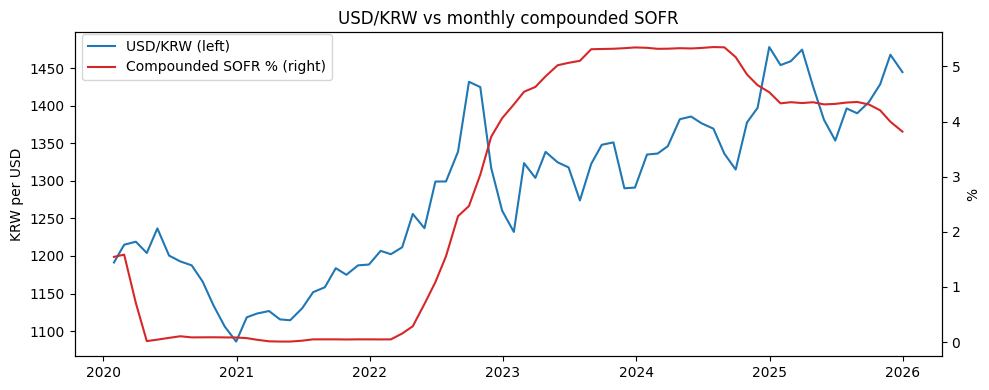

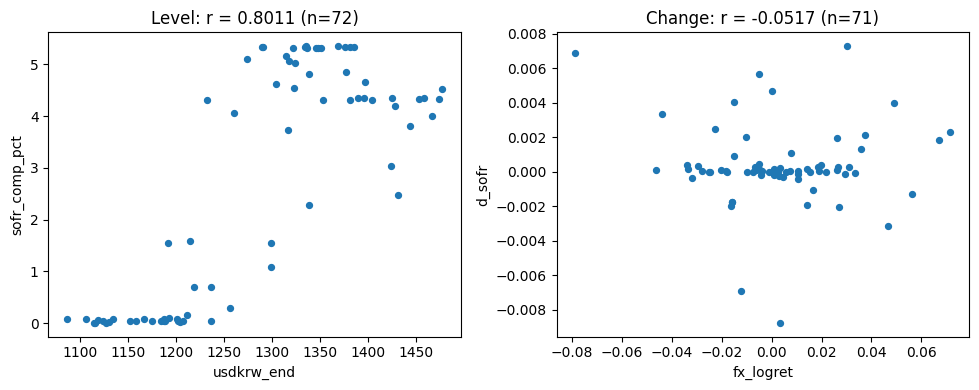

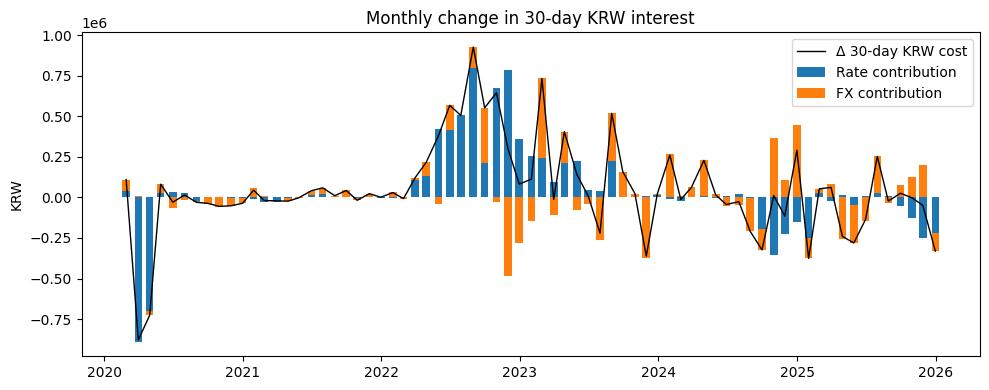

In [10]:
x = pd.to_datetime(m["end_date"])

# 1) 시계열 비교
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(x, m["usdkrw_end"], color="tab:blue", label="USD/KRW (left)")
ax1.set_ylabel("KRW per USD")
ax2 = ax1.twinx()
ax2.plot(x, m["sofr_comp_pct"], color="tab:red", label="Compounded SOFR % (right)")
ax2.set_ylabel("%")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
ax1.set_title("USD/KRW vs monthly compounded SOFR")
fig.tight_layout(); fig.savefig("figures/timeseries.png", dpi=150); plt.show()

# 2) 산점도 (수준값 / 변화값)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (xc, yc, t, name) in zip(axes, [
        ("usdkrw_end", "sofr_comp_pct", "Level", "level"),
        ("fx_logret", "d_sofr", "Change", "change")]):
    d = m[[xc, yc]].dropna()
    ax.scatter(d[xc], d[yc], s=18)
    ax.set_xlabel(xc); ax.set_ylabel(yc)
    ax.set_title(f"{t}: r = {d[xc].corr(d[yc]):.4f} (n={len(d)})")
    f2, a2 = plt.subplots(figsize=(5, 4)); a2.scatter(d[xc], d[yc], s=18)
    a2.set_xlabel(xc); a2.set_ylabel(yc); a2.set_title(f"{t}: r = {d[xc].corr(d[yc]):.4f}")
    f2.tight_layout(); f2.savefig(f"figures/scatter_{name}.png", dpi=150); plt.close(f2)
fig.tight_layout(); plt.show()

# 3) 월별 기여도
d = m.dropna(subset=["d_cost"]).copy()
dx = pd.to_datetime(d["end_date"])
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dx, d["contrib_rate"], width=20, label="Rate contribution")
same = (d["contrib_rate"] > 0) == (d["contrib_fx"] > 0)
ax.bar(dx, d["contrib_fx"], width=20, bottom=d["contrib_rate"].where(same, 0), label="FX contribution")
ax.plot(dx, d["d_cost"], color="black", lw=1, label="Δ 30-day KRW cost")
ax.set_ylabel("KRW"); ax.legend(); ax.set_title("Monthly change in 30-day KRW interest")
fig.tight_layout(); fig.savefig("figures/contribution.png", dpi=150); plt.show()

In [11]:
top = d.assign(abs_change=d["d_cost"].abs()).nlargest(5, "abs_change")
print("이자부담 변화가 컸던 5개월")
display(top[["month","d_cost","contrib_rate","contrib_fx","dominant"]].round(0))

print(f"""
[김동민] [monthly_analysis.csv · metrics.json {VERSION}]
- 표본: 공통일 {n_daily}일 → 월 끝점 {metrics['counts']['endpoints']} → 기간 {metrics['counts']['periods']} → 변화 {metrics['counts']['changes']}
- 수준값 상관 {metrics['corr_level']:+.4f} / 변화값 상관 {metrics['corr_change']:+.4f}
- 환율 기여 우세 {metrics['fx_dominant_months']}/{metrics['counts']['changes']}개월
- 기여 절댓값 합: 금리 {metrics['sum_abs_contrib_rate_krw']/1e6:.2f}백만원 / 환율 {metrics['sum_abs_contrib_fx_krw']/1e6:.2f}백만원
- 첨부: monthly_analysis.csv, metrics.json, figures 4종, analysis_core.py, 노트북
[할 일] 승연: 앱에 연결 (analysis_core import) / 윤호: 결과·해석 작성 / 지수: PPT 수치 반영
※ 모든 숫자는 이 metrics.json 기준. 차이 발견 시 위치·기대값을 동민·조장에게 회신""")

이자부담 변화가 컸던 5개월


,month,d_cost,contrib_rate,contrib_fx,dominant
31,2022-08,928343.0,799050.0,129293.0,RATE
2,2020-03,-878563.0,-889056.0,10493.0,RATE
37,2023-02,734676.0,244717.0,489959.0,FX
3,2020-04,-727317.0,-697827.0,-29490.0,RATE
33,2022-10,646305.0,674305.0,-27999.0,RATE



[김동민] [monthly_analysis.csv · metrics.json v1]
- 표본: 공통일 1493일 → 월 끝점 73 → 기간 72 → 변화 71
- 수준값 상관 +0.8011 / 변화값 상관 -0.0517
- 환율 기여 우세 44/71개월
- 기여 절댓값 합: 금리 9.72백만원 / 환율 8.00백만원
- 첨부: monthly_analysis.csv, metrics.json, figures 4종, analysis_core.py, 노트북
[할 일] 승연: 앱에 연결 (analysis_core import) / 윤호: 결과·해석 작성 / 지수: PPT 수치 반영
※ 모든 숫자는 이 metrics.json 기준. 차이 발견 시 위치·기대값을 동민·조장에게 회신


## ⑤ 재계산 확인 (기획서 사전 계산값과 대조)
2일 차에 이 셀까지 다시 실행해 전부 `OK`인지 확인합니다. 앱 화면 숫자도 같은 조건(2020-01~2025-12, 100만 달러, 2%)에서 이 표와 대조하세요.

In [12]:
EXPECTED = {"공통 유효일": 1493, "월 끝점": 73, "계산 기간": 72, "연속 변화": 71,
            "수준값 상관": 0.8011, "변화값 상관": -0.0517, "환율 우세 월": 44,
            "금리 기여 절댓값 합(백만원)": 9.72, "환율 기여 절댓값 합(백만원)": 8.00}
got = {"공통 유효일": n_daily, "월 끝점": metrics["counts"]["endpoints"],
       "계산 기간": metrics["counts"]["periods"], "연속 변화": metrics["counts"]["changes"],
       "수준값 상관": metrics["corr_level"], "변화값 상관": metrics["corr_change"],
       "환율 우세 월": metrics["fx_dominant_months"],
       "금리 기여 절댓값 합(백만원)": round(metrics["sum_abs_contrib_rate_krw"]/1e6, 2),
       "환율 기여 절댓값 합(백만원)": round(metrics["sum_abs_contrib_fx_krw"]/1e6, 2)}
check = pd.DataFrame({"기획서": EXPECTED, "이번 계산": got})
check["결과"] = np.where((check["기획서"] - check["이번 계산"]).abs() < 1e-9, "OK", "CHK")
display(check)
print("기여도 분해 최대 오차:", metrics["max_decomp_residual"], "(0에 가까워야 정상)")
if (check["결과"] == "CHK").any():
    print("CHK 항목이 있습니다. 원인 확인 후 VERSION을 올려 수정본을 공유하세요.")
else:
    print("모두 일치 → '기존 값 유지'로 전원에게 회신")

,기획서,이번 계산,결과
공통 유효일,1493.0000,1493.0000,OK
월 끝점,73.0000,73.0000,OK
계산 기간,72.0000,72.0000,OK
연속 변화,71.0000,71.0000,OK
수준값 상관,0.8011,0.8011,OK
변화값 상관,-0.0517,-0.0517,OK
환율 우세 월,44.0000,44.0000,OK
금리 기여 절댓값 합(백만원),9.7200,9.7200,OK
환율 기여 절댓값 합(백만원),8.0000,8.0000,OK


기여도 분해 최대 오차: 2.2519088815897703e-09 (0에 가까워야 정상)
모두 일치 → '기존 값 유지'로 전원에게 회신


## 결과 내려받기 (ZIP)

In [13]:
shutil.copy("analysis_core.py", "processed/analysis_core.py")
Path("requirements.txt").write_text("pandas>=2.0\nnumpy>=1.24\nmatplotlib>=3.7\n")
out = f"data_part_{VERSION}"
Path(out).mkdir(exist_ok=True)
for p in ["raw", "processed", "figures"]:
    shutil.copytree(p, f"{out}/{p}", dirs_exist_ok=True)
shutil.copy("requirements.txt", out)
shutil.make_archive(out, "zip", out)
print(f"{out}.zip 생성")
offer_download(f"{out}.zip")

data_part_v1.zip 생성
저장 위치: C:\Users\user\Desktop\1002\MODULE04_미니프로젝트03_2조\source\_run\data_part_v1.zip
